# DecoVAE-FM: окна сглаживания × KL × нормализация

Проверяем предложения **1, 2 и 4** из обсуждения: увеличить окна moving average,
ослабить KL / плавно включить его и заменить asinh линейной стандартизацией.
**Loss для компонент не добавляется.** Используем текущую `DecoVAEFM` и штатные
`training_step`, `_elbo_losses`, `configure_optimizers`, `predict_step`.

Полный план: 3 набора окон × 2 постоянных β × 2 нормализации = **12 запусков**;
дополнительно 2 запуска с `[125]` и KL warmup. Каждый — 30 эпох, 2048 train / 256 val,
контекст 512, горизонт 256, batch 32, learning rate 0.001.
Это сравнительный эксперимент на синтетике исходного ноутбука, не итоговый выбор
настройки для всех реальных данных. Все варианты используют одинаковые данные,
порядок батчей и начальные параметры общих слоёв.

После входной декомпозиции без обучения оцениваем обученные модели на **128 независимых
Dummy-окнах** и шести контрольных сигналах. Четыре исходных диагностических ряда
сохранены для графиков. Контрольные сигналы не участвуют в обучении.
`RUN_PROFILE="smoke"` оставлен для проверки исполнения; выводы ниже должны использовать full.

In [1]:
import os, sys, json, hashlib, inspect, platform, subprocess, time, gc
from pathlib import Path
from copy import deepcopy
from unittest.mock import patch
from itertools import product

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "decovaefm/models/decovae_fm.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Запустите ноутбук из корня проекта или notebooks/.")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import lightning as L
from IPython.display import display, Markdown
from torch.utils.data import DataLoader
from omegaconf import OmegaConf
from decovaefm.debug_data import DummyRandomDataset
from decovaefm.lightning_module import DecoVAEFMLightning

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.5g}")
RUN_PROFILE = "full"
SEED = 42
DATA_SEED = 1
MC_SAMPLES = 64
MC_BATCH = 16
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(min(4, os.cpu_count() or 1))
if RUN_PROFILE not in {"full", "smoke"}:
    raise ValueError(RUN_PROFILE)
N_TRAIN, N_VAL, N_TEST, EPOCHS = (2048, 256, 128, 30) if RUN_PROFILE == "full" else (128, 32, 16, 2)
config_paths = [ROOT / "configs" / group / "default.yaml" for group in ["data", "model"]]
config = OmegaConf.to_container(OmegaConf.merge(*[OmegaConf.load(p) for p in config_paths]), resolve=True)
config.update(pred_len=256, learning_rate=0.001, kl_weight=1.0)
T, H = config["context_len"], config["pred_len"]
assert config["stride"] == config["patch_size"] and T % config["stride"] == H % config["stride"] == 0
model_kwargs = {key: config[key] for key in inspect.signature(DecoVAEFMLightning.__init__).parameters if key in config}
KERNEL_SETS = {"short": [5,9,13,25], "wide125": [125], "multiscale": [65,125,255]}
VARIANTS = []
for kernel_name, beta, normalization in product(KERNEL_SETS, [1.0, 0.01], ["asinh", "linear"]):
    VARIANTS.append({"name": f"{kernel_name}_b{beta:g}_{normalization}", "kernel_name": kernel_name,
                     "kernels": KERNEL_SETS[kernel_name], "beta": beta,
                     "normalization": normalization, "schedule": "constant"})
for normalization in ["asinh", "linear"]:
    VARIANTS.append({"name": f"wide125_warmup_{normalization}", "kernel_name": "wide125",
                     "kernels": [125], "beta": 0.01, "normalization": normalization, "schedule": "warmup5"})
# Внешний runner может указать локальный progress-файл; обычному запуску это не требуется.
progress_path = os.environ.get("DECOVAE_ABLATION_PROGRESS")
def report_progress(event):
    event = dict(event, elapsed_clock=time.time())
    if progress_path:
        with open(progress_path, "a", encoding="utf-8") as f:
            f.write(json.dumps(event, ensure_ascii=False) + "\n")

source_paths = ["decovaefm/models/decovae_fm.py", "decovaefm/models/complex.py",
                "decovaefm/models/layers.py", "decovaefm/models/rope.py",
                "decovaefm/lightning_module.py", "decovaefm/debug_data.py"]
source_hashes = {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in source_paths}
provenance = {"git_revision": subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip(),
              "python": platform.python_version(), "torch": torch.__version__, "lightning": L.__version__,
              "device": DEVICE, "seed": SEED, "profile": RUN_PROFILE, "epochs_per_run": EPOCHS,
              "train_samples": N_TRAIN, "val_samples": N_VAL, "test_samples": N_TEST,
              "mc_samples": MC_SAMPLES, "model_kwargs": model_kwargs, "source_sha256": source_hashes,
              "variants": VARIANTS}
print(json.dumps(provenance, indent=2, ensure_ascii=False))
if platform.python_version_tuple()[:2] != ("3","11") or torch.__version__.split("+")[0] != "2.5.1":
    print("Среда отличается от pyproject.toml (Python 3.11 / torch 2.5.1); фактические версии записаны выше.")
display(pd.DataFrame(VARIANTS))

{
  "git_revision": "ee6d26e3450314c83a4818bee094aa6b92069797",
  "python": "3.13.5",
  "torch": "2.8.0",
  "lightning": "2.6.1",
  "device": "cpu",
  "seed": 42,
  "profile": "full",
  "epochs_per_run": 30,
  "train_samples": 2048,
  "val_samples": 256,
  "test_samples": 128,
  "mc_samples": 64,
  "model_kwargs": {
    "context_len": 512,
    "pred_len": 256,
    "d_model": 64,
    "patch_size": 16,
    "stride": 16,
    "n_heads": 4,
    "enc_layers": 2,
    "dec_layers": 2,
    "k_top": 16,
    "rope_theta": 10000.0,
    "kernels": [
      5,
      9,
      13,
      25
    ],
    "learning_rate": 0.001,
    "kl_weight": 1.0,
    "recon_weight": 1.0,
    "forecast_weight": 1.0
  },
  "source_sha256": {
    "decovaefm/models/decovae_fm.py": "64433ca1e3be72ec76b985377ea70d91ec1a62d458ff491341bd96ac7c7d53eb",
    "decovaefm/models/complex.py": "daf21ea3040abb27f23c0790147c7755d0362bd322e7ddb897f96fdd1b61157b",
    "decovaefm/models/layers.py": "742ac1031922b9de87e2e1c1286d3d28da7247f88

,name,kernel_name,kernels,beta,normalization,schedule
0,short_b1_asinh,short,"[5, 9, 13, 25]",1,asinh,constant
1,short_b1_linear,short,"[5, 9, 13, 25]",1,linear,constant
2,short_b0.01_asinh,short,"[5, 9, 13, 25]",0.01,asinh,constant
3,short_b0.01_linear,short,"[5, 9, 13, 25]",0.01,linear,constant
4,wide125_b1_asinh,wide125,[125],1,asinh,constant
5,wide125_b1_linear,wide125,[125],1,linear,constant
6,wide125_b0.01_asinh,wide125,[125],0.01,asinh,constant
7,wide125_b0.01_linear,wide125,[125],0.01,linear,constant
8,multiscale_b1_asinh,multiscale,"[65, 125, 255]",1,asinh,constant
9,multiscale_b1_linear,multiscale,"[65, 125, 255]",1,linear,constant


## Честное сравнение

Нелинейная нормализация не сохраняет исходную аддитивность. Для asinh oracle строится
телескопически в выбранном порядке: `F(T)`, `F(T+S)−F(T)`, `F(T+S+N)−F(T+S)`.
Для linear это точно `(T−mean)/std`, `S/std`, `N/std`.
Поэтому метрики компонент в asinh — диагностика в модельной шкале; linear позволяет
напрямую проверить исходное аддитивное разделение.

Главная общая метрика прогноза — RMSE **медианы штатных predictive samples в исходной шкале**,
делённая на std контекста каждой серии, затем усреднённая по сериям (`forecast_nrmse`).
Также измеряем покрытие 90% predictive interval и его ширину / std(context).
NLL между разными нормализациями не ранжируем.

`input_leak_abs` — средний **модуль** проекции ошибки входного тренда на истинную сезонность:
положительная и отрицательная утечки не должны взаимно сокращаться.
`decoded_season_gain` измеряет проекцию seasonal decoder на oracle seasonal;
нулевая сезонная ветвь даёт 0, правильно восстановленная — примерно 1.
Ошибки компонент делим на RMS полного нормализованного ряда.

In [2]:
class NormalizationAblation(DecoVAEFMLightning):
    # Меняем только нормализацию, без копирования/редактирования архитектуры и loss.
    def __init__(self, normalization="asinh", **kwargs):
        super().__init__(**kwargs)
        if normalization not in {"asinh", "linear"}:
            raise ValueError(normalization)
        self.normalization = normalization
    def _normalize(self, x, x_mean, x_std):
        if self.normalization == "linear":
            return (x-x_mean)/x_std
        return super()._normalize(x, x_mean, x_std)
    def _denormalize(self, x, x_mean, x_std):
        if self.normalization == "linear":
            return x*x_std+x_mean
        return super()._denormalize(x, x_mean, x_std)

assert NormalizationAblation._elbo_losses is DecoVAEFMLightning._elbo_losses
assert NormalizationAblation.training_step is DecoVAEFMLightning.training_step
assert NormalizationAblation.configure_optimizers is DecoVAEFMLightning.configure_optimizers

def make_dummy(n, noise_seed, global_seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(global_seed)
        ds = DummyRandomDataset(num_samples=n, context_len=T, pred_len=H, seed=noise_seed)
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(global_seed)
        span = torch.randint(20,70,(n,1))
        amplitude = torch.randint(1,10000,(n,1))
    phase = torch.linspace(0,1,T+H)[None,:]*span+torch.arange(n)[:,None]
    sine = torch.sin(phase)
    clean = sine*amplitude
    observed = torch.cat([ds.context,ds.target],1)
    eps = torch.randn(n,T+H,generator=torch.Generator().manual_seed(noise_seed))
    torch.testing.assert_close(observed,(sine+eps*(sine+1)*0.15)*amplitude,rtol=0,atol=0)
    parts = {"trend": torch.zeros_like(clean), "seasonal": clean, "noise": observed-clean}
    return {"context": ds.context, "target": ds.target, "full": observed, "parts": parts,
            "periods": ((T+H-1)*2*np.pi/span.squeeze(1)).numpy(), "dataset": ds}

train_data = make_dummy(N_TRAIN,DATA_SEED,SEED+10)
val_data = make_dummy(N_VAL,DATA_SEED+1,SEED+20)
test_data = make_dummy(N_TEST,DATA_SEED+2,SEED+30)
visual_data = make_dummy(4,DATA_SEED,SEED+30)

# Общие слои инициализируются один раз. Разное число окон иначе сдвинуло бы RNG
# и дало бы разные начальные веса всей сети — это лишний фактор эксперимента.
L.seed_everything(SEED, workers=True)
base_module = DecoVAEFMLightning(**model_kwargs)
base_state = {k:v.detach().cpu().clone() for k,v in base_module.state_dict().items()}
common_state = {k:v for k,v in base_state.items() if k != "model.decomposition.weights"}
base_weights = base_state["model.decomposition.weights"].clone()
common_init_sha = hashlib.sha256(b"".join(v.numpy().tobytes() for v in common_state.values())).hexdigest()
print("Shared neural initialization SHA256:", common_init_sha)
del base_module

def new_module(variant):
    kwargs = dict(model_kwargs, kernels=list(variant["kernels"]), kl_weight=variant["beta"], num_samples=MC_SAMPLES)
    module = NormalizationAblation(normalization=variant["normalization"], **kwargs)
    missing, unexpected = module.load_state_dict(common_state, strict=False)
    assert missing == ["model.decomposition.weights"] and not unexpected
    with torch.no_grad():
        if variant["kernels"] == KERNEL_SETS["short"]:
            module.model.decomposition.weights.copy_(base_weights)
        else:
            # Новые multi-scale окна начинают с равных весов; single-window вес равен 1.
            module.model.decomposition.weights.zero_()
    return module.to(DEVICE)

def model_view(module,data):
    x=data["context"].to(DEVICE)
    mean,std=module._get_normalization_stats(x)
    xnorm=module._normalize(x,mean,std)
    yt=data["target"].to(DEVICE)
    ynorm=module._normalize(yt,mean,std)
    parts={k:v.to(DEVICE) for k,v in data["parts"].items()}
    ft=module._normalize(parts["trend"],mean,std)
    fts=module._normalize(parts["trend"]+parts["seasonal"],mean,std)
    fall=module._normalize(data["full"].to(DEVICE),mean,std)
    truth={"trend":ft.cpu(),"seasonal":(fts-ft).cpu(),"noise":(fall-fts).cpu()}
    torch.testing.assert_close(sum(truth.values()),fall.cpu(),rtol=1e-5,atol=2e-6)
    return xnorm,ynorm,truth,mean.cpu(),std.cpu()

def rms_rows(x):
    return torch.sqrt(torch.mean(x.float()**2,dim=1))
def gain_rows(a,b):
    a=a.float()-a.float().mean(1,keepdim=True)
    b=b.float()-b.float().mean(1,keepdim=True)
    denom=(b*b).sum(1)
    return torch.where(denom>1e-10,(a*b).sum(1)/denom.clamp_min(1e-10),torch.nan)
def finite_mean(x):
    x=x[torch.isfinite(x)]
    return float(x.mean()) if x.numel() else np.nan

def encode_components(module,xnorm):
    module.eval()
    with torch.inference_mode():
        enc=module.model.encode(xnorm)
    parts={"trend":enc["target_trend"].cpu(),"seasonal":enc["target_seasonal"].cpu()}
    parts["noise"]=xnorm.cpu()-parts["trend"]-parts["seasonal"]
    torch.testing.assert_close(sum(parts.values()),xnorm.cpu(),rtol=1e-5,atol=2e-6)
    return parts

def decomposition_scores(parts,truth,xnorm,prefix="input"):
    scale=rms_rows(xnorm.cpu()).clamp_min(1e-8)
    length=xnorm.shape[1]
    true_t=truth["trend"][:,:length]
    true_s=truth["seasonal"][:,:length]
    leakage=gain_rows(parts["trend"]-true_t,true_s)
    row={prefix+"_leak_abs":finite_mean(leakage.abs()),
         prefix+"_trend_gain":finite_mean(leakage),
         prefix+"_season_gain":finite_mean(gain_rows(parts["seasonal"],true_s))}
    for name in ["trend","seasonal","noise"]:
        row[prefix+"_"+name+"_nrmse"]=float((rms_rows(parts[name]-truth[name][:,:length])/scale).mean())
    # Одинаковый край 127 для всех вариантов, чтобы сравнение не меняло набор отсчётов.
    common_edge=max(max(k) for k in KERNEL_SETS.values())//2
    sl=slice(common_edge,length-common_edge)
    row[prefix+"_leak_abs_interior"]=finite_mean(gain_rows(parts["trend"][:,sl]-true_t[:,sl],true_s[:,sl]).abs())
    return row

# Включаем известные тренд/шум; эти стресс-тесты не являются обучающей выборкой.
t=torch.arange(T+H,dtype=torch.float32)
g=torch.Generator().manual_seed(SEED+70)
zeros=torch.zeros(T+H)
control_parts=[]
def add_case(name,trend,seasonal,noise):
    control_parts.append(dict(name=name,trend=trend,seasonal=seasonal,noise=noise))
add_case("sine16",zeros,torch.sin(2*torch.pi*t/16),zeros)
add_case("sine128",zeros,torch.sin(2*torch.pi*t/128),zeros)
ss=torch.sin(2*torch.pi*t/128)
add_case("trend_sine_noise",0.004*(t-(T-1)/2),ss,torch.randn(T+H,generator=g)*0.15*(ss+1))
add_case("white_noise",zeros,zeros,torch.randn(T+H,generator=g)*0.3)
add_case("offgrid97",zeros,torch.sin(2*torch.pi*t/97),zeros)
add_case("level_shift",(t>=T//2).float()-0.5,torch.sin(2*torch.pi*t/32),torch.randn(T+H,generator=g)*0.08)
control_names=[c["name"] for c in control_parts]
control_truth={k:torch.stack([c[k] for c in control_parts]) for k in ["trend","seasonal","noise"]}
control_full=sum(control_truth.values())
control_data={"context":control_full[:,:T],"target":control_full[:,T:],"full":control_full,"parts":control_truth}

Shared neural initialization SHA256: 0b8d63e85df6231893d4614d202f8f1520dc654b0996007245c589009a68114a


## 1. Проверка фильтра до обучения

Меняем только окна и нормализацию; β на `core.encode` без обучения не влияет.
Показываем также ошибки на настоящем линейном тренде и скачке уровня: более широкое
сглаживание может улучшить отделение сезонности ценой размытия изменений тренда.

Operator-only results: [{"kernel":"short","normalization":"asinh","input_leak_abs":0.9526743889,"input_trend_gain":0.9526743889,"input_season_gain":0.0251337625,"input_trend_nrmse":0.944750905,"input_seasonal_nrmse":0.9701988697,"input_noise_nrmse":0.1250877678,"input_leak_abs_interior":0.9504079819},{"kernel":"short","normalization":"linear","input_leak_abs":0.965113461,"input_trend_gain":0.965113461,"input_season_gain":0.0248114914,"input_trend_nrmse":0.9377077818,"input_seasonal_nrmse":0.9522877336,"input_noise_nrmse":0.1379114389,"input_leak_abs_interior":0.9622117877},{"kernel":"wide125","normalization":"asinh","input_leak_abs":0.1987536848,"input_trend_gain":0.0219021067,"input_season_gain":0.9581366777,"input_trend_nrmse":0.2626410723,"input_seasonal_nrmse":0.2882117629,"input_noise_nrmse":0.1257497668,"input_leak_abs_interior":0.2120360881},{"kernel":"wide125","normalization":"linear","input_leak_abs":0.2017109692,"input_trend_gain":0.0225191135,"input_season_gain":0.96925807,"

,kernel,normalization,input_leak_abs,input_trend_gain,input_season_gain,input_trend_nrmse,input_seasonal_nrmse,input_noise_nrmse,input_leak_abs_interior
0,short,asinh,0.95267,0.95267,0.025134,0.94475,0.9702,0.12509,0.95041
1,short,linear,0.96511,0.96511,0.024811,0.93771,0.95229,0.13791,0.96221
2,wide125,asinh,0.19875,0.021902,0.95814,0.26264,0.28821,0.12575,0.21204
3,wide125,linear,0.20171,0.022519,0.96926,0.25807,0.29066,0.13714,0.21481
4,multiscale,asinh,0.16626,0.16143,0.81946,0.21571,0.25741,0.11931,0.15409
5,multiscale,linear,0.16887,0.16399,0.82875,0.2108,0.25236,0.13069,0.15629


,kernel,normalization,case,input_leak_abs,input_trend_nrmse,input_seasonal_nrmse
0,short,asinh,sine16,0.37233,0.37763,0.37367
1,short,asinh,sine128,0.97839,0.97866,0.97845
2,short,asinh,trend_sine_noise,0.98176,0.84935,0.86822
3,short,asinh,white_noise,NaN,0.32108,0.44345
4,short,asinh,offgrid97,0.96222,0.96461,0.96583
5,short,asinh,level_shift,0.71498,0.60463,0.60576
6,short,linear,sine16,0.37287,0.3778,0.37396
7,short,linear,sine128,0.97858,0.97877,0.97861
8,short,linear,trend_sine_noise,0.98546,0.83264,0.84826
9,short,linear,white_noise,NaN,0.31495,0.43806


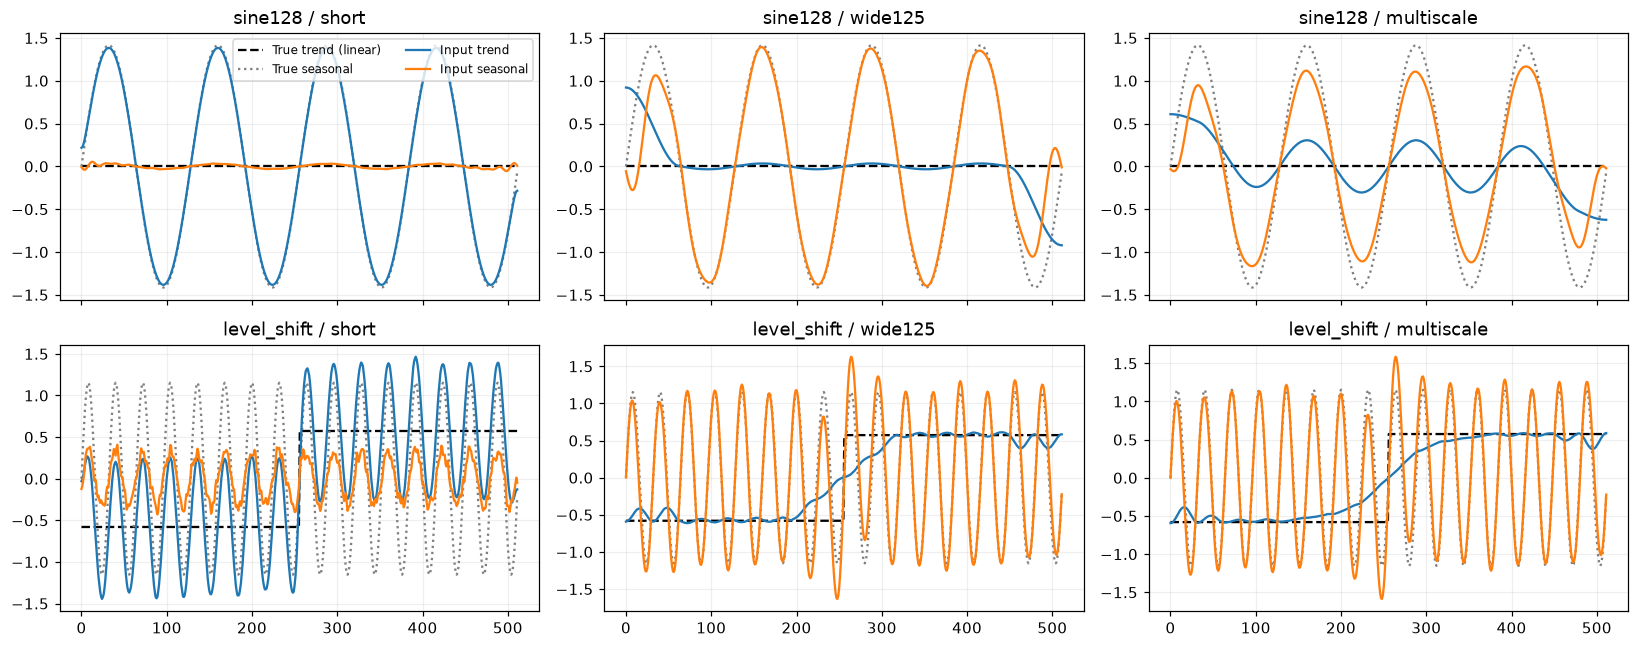

In [3]:
operator_rows=[]
operator_controls=[]
operator_examples={}
for kernel_name,normalization in product(KERNEL_SETS,["asinh","linear"]):
    v=dict(name=f"{kernel_name}_{normalization}",kernel_name=kernel_name,kernels=KERNEL_SETS[kernel_name],
           normalization=normalization,beta=1.0,schedule="constant")
    module=new_module(v).eval()
    xn,yn,truth,mean,std=model_view(module,test_data)
    parts=encode_components(module,xn)
    operator_rows.append(dict(kernel=kernel_name,normalization=normalization,
                              **decomposition_scores(parts,truth,xn)))
    xn,yn,truth,mean,std=model_view(module,control_data)
    parts=encode_components(module,xn)
    operator_examples[(kernel_name,normalization)]={"parts":parts,"truth":truth,"xnorm":xn.cpu()}
    for i,name in enumerate(control_names):
        pp={k:a[i:i+1] for k,a in parts.items()}
        tt={k:a[i:i+1] for k,a in truth.items()}
        operator_controls.append(dict(kernel=kernel_name,normalization=normalization,case=name,
                                      **decomposition_scores(pp,tt,xn[i:i+1])))
    del module
operator_table=pd.DataFrame(operator_rows)
operator_control_table=pd.DataFrame(operator_controls)
display(operator_table)
display(operator_control_table[["kernel","normalization","case","input_leak_abs","input_trend_nrmse","input_seasonal_nrmse"]])
fig,axes=plt.subplots(2,3,figsize=(15,6),sharex=True)
for row,name in enumerate(["sine128","level_shift"]):
    idx=control_names.index(name)
    for col,kernel_name in enumerate(KERNEL_SETS):
        e=operator_examples[(kernel_name,"linear")]
        ax=axes[row,col]
        ax.plot(e["truth"]["trend"][idx,:T],"k--",label="True trend (linear)")
        ax.plot(e["truth"]["seasonal"][idx,:T],color="gray",ls=":",label="True seasonal")
        ax.plot(e["parts"]["trend"][idx],label="Input trend",color="tab:blue")
        ax.plot(e["parts"]["seasonal"][idx],label="Input seasonal",color="tab:orange")
        ax.set_title(f"{name} / {kernel_name}")
axes[0,0].legend(fontsize=8,ncol=2)
fig.tight_layout()
plt.show()
print("Operator-only results:",operator_table.to_json(orient="records"))
report_progress({"event":"operator_complete","results":operator_rows})

## 2. Обучение и оценка

Во всех запусках используется последний epoch, без early stopping и выбора весов по test.
Начальная инициализация нейронных слоёв совпадает; для текущих четырёх окон сохранены
исходные случайные веса смеси, для новых трёх окон стартовая смесь равномерна.
β warmup растёт от 0 на первой эпохе до 0.01 на пятой, затем остаётся постоянным.

На validation сравниваем диагностический forward по средним латентам в исходной шкале
(`val_point_nrmse`); это не математическое ожидание прогнозного распределения после sinh.
На test используем медиану **полного** predictive sampling, включая шум наблюдения.
Для графиков компоненты остаются в модельной шкале — отдельные компоненты через sinh
не денормализуем. Noise decoder не выдаёт шумовой ряд: сравниваем входной residual
с known noise, а выход декодера показывает Gaussian std.

In [4]:
class RunHistory(L.Callback):
    def __init__(self,variant):
        self.variant=variant
        self.rows=[]
    def on_train_epoch_start(self,trainer,pl_module):
        if self.variant["schedule"]=="warmup5":
            pl_module.kl_weight=self.variant["beta"]*min(1.0,trainer.current_epoch/4)
    def on_validation_epoch_end(self,trainer,pl_module):
        if trainer.sanity_checking:
            return
        row={"epoch":trainer.current_epoch+1,"beta":float(pl_module.kl_weight)}
        for k in ["val_loss","val_recon_loss","val_forecast_loss","val_kl_loss"]:
            row[k]=float(trainer.callback_metrics[k].detach().cpu())
        self.rows.append(row)
        if row["epoch"]==1 or row["epoch"]%5==0:
            print(f"{self.variant['name']} epoch={row['epoch']} beta={row['beta']:.4g} val_loss={row['val_loss']:.4g}")
            report_progress({"event":"epoch","run":self.variant["name"],**row})

def decoded_forward(module,xnorm):
    module.eval()
    with torch.inference_mode(),patch.object(module.model,"reparameterize",side_effect=lambda mu,logvar:mu):
        out={k:v.cpu() for k,v in module.model(xnorm,pred_len=H).items()}
    assert "reparameterize" not in module.model.__dict__
    for k,v in out.items():
        assert torch.isfinite(v).all(),k
    torch.testing.assert_close(out["recon_mu"],(out["decoded_trend"]+out["decoded_seasonal"])[:,:T])
    return out

def decoder_scores(module,xnorm,ynorm,truth,out):
    d={"trend":out["decoded_trend"][:,:T],"seasonal":out["decoded_seasonal"][:,:T]}
    d["noise"]=xnorm.cpu()-d["trend"]-d["seasonal"]
    row=decomposition_scores(d,truth,xnorm,prefix="decoded")
    # Поле decoded_noise — residual среднего, не отдельный выход декодера.
    row["seasonal_to_trend_rms"]=float((rms_rows(d["seasonal"])/rms_rows(d["trend"]).clamp_min(1e-8)).mean())
    for branch in ["trend","seasonal","noise"]:
        row["kl_"+branch]=float(module._kl_divergence(out[branch+"_mu"],out[branch+"_logvar"]))
    row["point_recon_nrmse_model"]=float((rms_rows(out["recon_mu"]-xnorm.cpu())/rms_rows(xnorm.cpu()).clamp_min(1e-8)).mean())
    return row

def predictive_metrics(module,data):
    recon_median=[]; forecast_median=[]; lo=[]; hi=[]
    cuda_ids=[torch.cuda.current_device()] if DEVICE=="cuda" else []
    with torch.random.fork_rng(devices=cuda_ids):
        torch.manual_seed(SEED+60)
        for start in range(0,len(data["context"]),MC_BATCH):
            x=data["context"][start:start+MC_BATCH].to(DEVICE)
            y=data["target"][start:start+MC_BATCH].to(DEVICE)
            with torch.inference_mode():
                pred=module.predict_step((x,y),batch_idx=start//MC_BATCH)
                fs=pred["forecast_samples"].cpu()
                rs=pred["recon_samples"].cpu()
            assert torch.isfinite(fs).all() and torch.isfinite(rs).all()
            q=torch.quantile(fs,torch.tensor([0.05,0.5,0.95]),dim=1)
            recon_median.append(torch.quantile(rs,0.5,dim=1))
            lo.append(q[0]); forecast_median.append(q[1]); hi.append(q[2])
    med=torch.cat(forecast_median); low=torch.cat(lo); high=torch.cat(hi); rec=torch.cat(recon_median)
    target=data["target"]
    scale=data["context"].std(1,unbiased=False).clamp_min(1e-5)
    per_window=rms_rows(med-target)/scale
    metrics={"forecast_nrmse":float(per_window.mean()),
             "forecast_nrmse_p90":float(torch.quantile(per_window,0.9)),
             "recon_nrmse":float((rms_rows(rec-data["context"])/scale).mean()),
             "coverage90":float(((target>=low)&(target<=high)).float().mean()),
             "width90_scaled":float(((high-low).mean(1)/scale).mean())}
    return metrics,{"median":med,"lo":low,"hi":high,"recon_median":rec,"per_window_nrmse":per_window}

results=[]; histories={}; visuals={}; per_window_results=[]; trained_control_rows=[]; trained_control_outputs={}
def execute_variant(v):
    start=time.perf_counter()
    report_progress({"event":"run_start","run":v["name"]})
    module=new_module(v)
    # Проверяем совпадение общей инициализации до начала оптимизации.
    for k,reference in common_state.items():
        torch.testing.assert_close(module.state_dict()[k].cpu(),reference,rtol=0,atol=0)
    xn,yn,truth,mean,std=model_view(module,test_data)
    before=decomposition_scores(encode_components(module,xn),truth,xn)
    callback=RunHistory(v)
    train_loader=DataLoader(train_data["dataset"],batch_size=config["batch_size"],shuffle=True,num_workers=0,
                            generator=torch.Generator().manual_seed(SEED+40))
    val_loader=DataLoader(val_data["dataset"],batch_size=config["batch_size"],shuffle=False,num_workers=0)
    L.seed_everything(SEED+50,workers=True)
    trainer=L.Trainer(max_epochs=EPOCHS,accelerator="gpu" if DEVICE=="cuda" else "cpu",devices=1,
                       logger=False,enable_checkpointing=False,enable_progress_bar=False,
                       enable_model_summary=False,num_sanity_val_steps=0,callbacks=[callback])
    trainer.fit(module,train_loader,val_loader)
    assert len(callback.rows)==EPOCHS
    histories[v["name"]]=pd.DataFrame(callback.rows)
    module.eval()
    xn,yn,truth,mean,std=model_view(module,test_data)
    parts=encode_components(module,xn)
    out=decoded_forward(module,xn)
    row={"run":v["name"],"kernel":v["kernel_name"],"normalization":v["normalization"],
         "beta":v["beta"],"schedule":v["schedule"],"epochs":EPOCHS,
         "initial_input_leak_abs":before["input_leak_abs"],
         **decomposition_scores(parts,truth,xn),**decoder_scores(module,xn,yn,truth,out)}
    row["kernel_weights"]=torch.softmax(module.model.decomposition.weights.detach(),0).cpu().tolist()
    xn_v,yn_v,truth_v,mean_v,std_v=model_view(module,val_data)
    out_v=decoded_forward(module,xn_v)
    point_v=module._denormalize(out_v["forecast_mu"].to(DEVICE),mean_v.to(DEVICE),std_v.to(DEVICE)).cpu()
    row["val_point_nrmse"]=float((rms_rows(point_v-val_data["target"])/std_v.squeeze(1)).mean())
    metrics,predictive=predictive_metrics(module,test_data)
    row.update(metrics)
    for i,e in enumerate(predictive["per_window_nrmse"].tolist()):
        per_window_results.append({"run":v["name"],"sample":i,"period":float(test_data["periods"][i]),"forecast_nrmse":e})
    xn_p,yn_p,truth_p,mean_p,std_p=model_view(module,visual_data)
    visuals[v["name"]]={"out":decoded_forward(module,xn_p),"truth":truth_p,
                         "full_norm":torch.cat([xn_p,yn_p],1).cpu(),
                         "input_parts":encode_components(module,xn_p)}
    xn_c,yn_c,truth_c,mean_c,std_c=model_view(module,control_data)
    cp=encode_components(module,xn_c); co=decoded_forward(module,xn_c)
    trained_control_outputs[v["name"]]={"parts":cp,"out":co,"truth":truth_c,"xnorm":xn_c.cpu()}
    for i,name in enumerate(control_names):
        pp={k:a[i:i+1] for k,a in cp.items()}; tt={k:a[i:i+1] for k,a in truth_c.items()}
        dd={"trend":co["decoded_trend"][i:i+1,:T],"seasonal":co["decoded_seasonal"][i:i+1,:T]}
        dd["noise"]=xn_c[i:i+1].cpu()-dd["trend"]-dd["seasonal"]
        trained_control_rows.append({"run":v["name"],"case":name,
                                     **decomposition_scores(pp,tt,xn_c[i:i+1]),
                                     **decomposition_scores(dd,tt,xn_c[i:i+1],"decoded")})
    row["seconds"]=time.perf_counter()-start
    results.append(row)
    report_progress({"event":"run_complete","run":v["name"],"completed":len(results),"metrics":row})
    print(json.dumps(row,indent=2,ensure_ascii=False))
    del module,trainer,xn,out,parts
    gc.collect()
    if DEVICE=="cuda": torch.cuda.empty_cache()
    return row

In [5]:
row_0 = execute_variant(VARIANTS[0])
display(pd.DataFrame([row_0])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

short_b1_asinh epoch=1 beta=1 val_loss=1.52
short_b1_asinh epoch=5 beta=1 val_loss=0.9483
short_b1_asinh epoch=10 beta=1 val_loss=-0.2573
short_b1_asinh epoch=15 beta=1 val_loss=-0.6826
short_b1_asinh epoch=20 beta=1 val_loss=-0.8171
short_b1_asinh epoch=25 beta=1 val_loss=-0.09877
short_b1_asinh epoch=30 beta=1 val_loss=-0.9252
{
  "run": "short_b1_asinh",
  "kernel": "short",
  "normalization": "asinh",
  "beta": 1.0,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.952674388885498,
  "input_leak_abs": 0.9532303810119629,
  "input_trend_gain": 0.9532303810119629,
  "input_season_gain": 0.024470554664731026,
  "input_trend_nrmse": 0.9453016519546509,
  "input_seasonal_nrmse": 0.9708524942398071,
  "input_noise_nrmse": 0.12516632676124573,
  "input_leak_abs_interior": 0.9509678483009338,
  "decoded_leak_abs": 0.9918480515480042,
  "decoded_trend_gain": 0.9918480515480042,
  "decoded_season_gain": 3.3560087331352406e-07,
  "decoded_trend_nrmse": 0.9834065437316895

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,short_b1_asinh,0.95323,3.356e-07,4.316e-05,0.29122,0.89087


In [6]:
row_1 = execute_variant(VARIANTS[1])
display(pd.DataFrame([row_1])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

short_b1_linear epoch=1 beta=1 val_loss=2.063
short_b1_linear epoch=5 beta=1 val_loss=0.9
short_b1_linear epoch=10 beta=1 val_loss=0.1239
short_b1_linear epoch=15 beta=1 val_loss=-0.1352
short_b1_linear epoch=20 beta=1 val_loss=-0.2264
short_b1_linear epoch=25 beta=1 val_loss=-0.3407
short_b1_linear epoch=30 beta=1 val_loss=-0.4694
{
  "run": "short_b1_linear",
  "kernel": "short",
  "normalization": "linear",
  "beta": 1.0,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.9651134610176086,
  "input_leak_abs": 0.9656660556793213,
  "input_trend_gain": 0.9656660556793213,
  "input_season_gain": 0.0241466723382473,
  "input_trend_nrmse": 0.9382505416870117,
  "input_seasonal_nrmse": 0.9529295563697815,
  "input_noise_nrmse": 0.13805237412452698,
  "input_leak_abs_interior": 0.9627680778503418,
  "decoded_leak_abs": 1.0092254877090454,
  "decoded_trend_gain": 1.0092254877090454,
  "decoded_season_gain": 2.1186078811297193e-06,
  "decoded_trend_nrmse": 0.980515003204

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,short_b1_linear,0.96567,2.1186e-06,0.0001678,0.27703,0.87393


In [7]:
row_2 = execute_variant(VARIANTS[2])
display(pd.DataFrame([row_2])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

short_b0.01_asinh epoch=1 beta=0.01 val_loss=0.8274
short_b0.01_asinh epoch=5 beta=0.01 val_loss=0.5555
short_b0.01_asinh epoch=10 beta=0.01 val_loss=0.0227
short_b0.01_asinh epoch=15 beta=0.01 val_loss=-0.9001
short_b0.01_asinh epoch=20 beta=0.01 val_loss=-0.9731
short_b0.01_asinh epoch=25 beta=0.01 val_loss=-1.265
short_b0.01_asinh epoch=30 beta=0.01 val_loss=-1.264
{
  "run": "short_b0.01_asinh",
  "kernel": "short",
  "normalization": "asinh",
  "beta": 0.01,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.952674388885498,
  "input_leak_abs": 0.9574849009513855,
  "input_trend_gain": 0.9574849009513855,
  "input_season_gain": 0.02090328186750412,
  "input_trend_nrmse": 0.9496604204177856,
  "input_seasonal_nrmse": 0.9743452072143555,
  "input_noise_nrmse": 0.1258620321750641,
  "input_leak_abs_interior": 0.9552459120750427,
  "decoded_leak_abs": 1.0036882162094116,
  "decoded_trend_gain": 1.0036882162094116,
  "decoded_season_gain": 0.00021426982129924,
  "d

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,short_b0.01_asinh,0.95748,0.00021427,0.0021716,0.29631,0.89282


In [8]:
row_3 = execute_variant(VARIANTS[3])
display(pd.DataFrame([row_3])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

short_b0.01_linear epoch=1 beta=0.01 val_loss=1.159
short_b0.01_linear epoch=5 beta=0.01 val_loss=0.8409
short_b0.01_linear epoch=10 beta=0.01 val_loss=0.271
short_b0.01_linear epoch=15 beta=0.01 val_loss=-0.2813
short_b0.01_linear epoch=20 beta=0.01 val_loss=-0.4048
short_b0.01_linear epoch=25 beta=0.01 val_loss=-0.6265
short_b0.01_linear epoch=30 beta=0.01 val_loss=-0.6748
{
  "run": "short_b0.01_linear",
  "kernel": "short",
  "normalization": "linear",
  "beta": 0.01,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.9651134610176086,
  "input_leak_abs": 0.9704276323318481,
  "input_trend_gain": 0.9704276323318481,
  "input_season_gain": 0.01858799159526825,
  "input_trend_nrmse": 0.9431499242782593,
  "input_seasonal_nrmse": 0.9582988023757935,
  "input_noise_nrmse": 0.13990657031536102,
  "input_leak_abs_interior": 0.9675538539886475,
  "decoded_leak_abs": 0.9868038892745972,
  "decoded_trend_gain": 0.9868038892745972,
  "decoded_season_gain": 0.000317749159

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,short_b0.01_linear,0.97043,0.00031775,0.0035161,0.29647,0.85129


In [9]:
row_4 = execute_variant(VARIANTS[4])
display(pd.DataFrame([row_4])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

wide125_b1_asinh epoch=1 beta=1 val_loss=12.57
wide125_b1_asinh epoch=5 beta=1 val_loss=1.05
wide125_b1_asinh epoch=10 beta=1 val_loss=-0.0003904
wide125_b1_asinh epoch=15 beta=1 val_loss=-0.2479
wide125_b1_asinh epoch=20 beta=1 val_loss=-0.4668
wide125_b1_asinh epoch=25 beta=1 val_loss=-0.4982
wide125_b1_asinh epoch=30 beta=1 val_loss=-0.6448
{
  "run": "wide125_b1_asinh",
  "kernel": "wide125",
  "normalization": "asinh",
  "beta": 1.0,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.19875368475914001,
  "input_leak_abs": 0.19875368475914001,
  "input_trend_gain": 0.02190210670232773,
  "input_season_gain": 0.9581366777420044,
  "input_trend_nrmse": 0.2626410722732544,
  "input_seasonal_nrmse": 0.28821176290512085,
  "input_noise_nrmse": 0.12574976682662964,
  "input_leak_abs_interior": 0.21203608810901642,
  "decoded_leak_abs": 0.9595914483070374,
  "decoded_trend_gain": 0.9595914483070374,
  "decoded_season_gain": -0.0001242638099938631,
  "decoded_trend_nrm

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,wide125_b1_asinh,0.19875,-0.00012426,0.00041963,0.31248,0.88992


In [10]:
row_5 = execute_variant(VARIANTS[5])
display(pd.DataFrame([row_5])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

wide125_b1_linear epoch=1 beta=1 val_loss=17.49
wide125_b1_linear epoch=5 beta=1 val_loss=1.745
wide125_b1_linear epoch=10 beta=1 val_loss=0.6819
wide125_b1_linear epoch=15 beta=1 val_loss=0.3604
wide125_b1_linear epoch=20 beta=1 val_loss=0.07883
wide125_b1_linear epoch=25 beta=1 val_loss=-0.03895
wide125_b1_linear epoch=30 beta=1 val_loss=-0.1336
{
  "run": "wide125_b1_linear",
  "kernel": "wide125",
  "normalization": "linear",
  "beta": 1.0,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.20171096920967102,
  "input_leak_abs": 0.20171096920967102,
  "input_trend_gain": 0.02251911349594593,
  "input_season_gain": 0.9692580699920654,
  "input_trend_nrmse": 0.25806719064712524,
  "input_seasonal_nrmse": 0.2906554937362671,
  "input_noise_nrmse": 0.13713625073432922,
  "input_leak_abs_interior": 0.21481215953826904,
  "decoded_leak_abs": 0.971101701259613,
  "decoded_trend_gain": 0.971101701259613,
  "decoded_season_gain": 3.0140794478938915e-05,
  "decoded_trend

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,wide125_b1_linear,0.20171,3.0141e-05,0.00035359,0.3097,0.86432


In [11]:
row_6 = execute_variant(VARIANTS[6])
display(pd.DataFrame([row_6])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

wide125_b0.01_asinh epoch=1 beta=0.01 val_loss=2.213
wide125_b0.01_asinh epoch=5 beta=0.01 val_loss=0.5888
wide125_b0.01_asinh epoch=10 beta=0.01 val_loss=-0.2069
wide125_b0.01_asinh epoch=15 beta=0.01 val_loss=-0.5112
wide125_b0.01_asinh epoch=20 beta=0.01 val_loss=-0.7046
wide125_b0.01_asinh epoch=25 beta=0.01 val_loss=-0.8299
wide125_b0.01_asinh epoch=30 beta=0.01 val_loss=-0.9391
{
  "run": "wide125_b0.01_asinh",
  "kernel": "wide125",
  "normalization": "asinh",
  "beta": 0.01,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.19875368475914001,
  "input_leak_abs": 0.19875368475914001,
  "input_trend_gain": 0.02190210670232773,
  "input_season_gain": 0.9581366777420044,
  "input_trend_nrmse": 0.2626410722732544,
  "input_seasonal_nrmse": 0.28821176290512085,
  "input_noise_nrmse": 0.12574976682662964,
  "input_leak_abs_interior": 0.21203608810901642,
  "decoded_leak_abs": 0.9671061038970947,
  "decoded_trend_gain": 0.9671061038970947,
  "decoded_season_gain":

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,wide125_b0.01_asinh,0.19875,0.0016563,0.0031833,0.29695,0.88223


In [12]:
row_7 = execute_variant(VARIANTS[7])
display(pd.DataFrame([row_7])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

wide125_b0.01_linear epoch=1 beta=0.01 val_loss=2.543
wide125_b0.01_linear epoch=5 beta=0.01 val_loss=0.9594
wide125_b0.01_linear epoch=10 beta=0.01 val_loss=0.4239
wide125_b0.01_linear epoch=15 beta=0.01 val_loss=0.1744
wide125_b0.01_linear epoch=20 beta=0.01 val_loss=-0.07838
wide125_b0.01_linear epoch=25 beta=0.01 val_loss=-0.1941
wide125_b0.01_linear epoch=30 beta=0.01 val_loss=-0.325
{
  "run": "wide125_b0.01_linear",
  "kernel": "wide125",
  "normalization": "linear",
  "beta": 0.01,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.20171096920967102,
  "input_leak_abs": 0.20171096920967102,
  "input_trend_gain": 0.02251911349594593,
  "input_season_gain": 0.9692580699920654,
  "input_trend_nrmse": 0.25806719064712524,
  "input_seasonal_nrmse": 0.2906554937362671,
  "input_noise_nrmse": 0.13713625073432922,
  "input_leak_abs_interior": 0.21481215953826904,
  "decoded_leak_abs": 0.9551900029182434,
  "decoded_trend_gain": 0.9551900029182434,
  "decoded_season

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,wide125_b0.01_linear,0.20171,0.00092864,0.0029106,0.30907,0.89383


In [13]:
row_8 = execute_variant(VARIANTS[8])
display(pd.DataFrame([row_8])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

multiscale_b1_asinh epoch=1 beta=1 val_loss=6.203
multiscale_b1_asinh epoch=5 beta=1 val_loss=1.584
multiscale_b1_asinh epoch=10 beta=1 val_loss=0.6289
multiscale_b1_asinh epoch=15 beta=1 val_loss=0.2119
multiscale_b1_asinh epoch=20 beta=1 val_loss=-0.08176
multiscale_b1_asinh epoch=25 beta=1 val_loss=-0.2027
multiscale_b1_asinh epoch=30 beta=1 val_loss=-0.2961
{
  "run": "multiscale_b1_asinh",
  "kernel": "multiscale",
  "normalization": "asinh",
  "beta": 1.0,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.16626334190368652,
  "input_leak_abs": 0.1742592751979828,
  "input_trend_gain": 0.1709718108177185,
  "input_season_gain": 0.8099427223205566,
  "input_trend_nrmse": 0.22236879169940948,
  "input_seasonal_nrmse": 0.2636716961860657,
  "input_noise_nrmse": 0.11931648850440979,
  "input_leak_abs_interior": 0.16139641404151917,
  "decoded_leak_abs": 0.9183173179626465,
  "decoded_trend_gain": 0.9183173179626465,
  "decoded_season_gain": 1.5498844732064754e-05

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,multiscale_b1_asinh,0.17426,1.5499e-05,0.00091807,0.40028,0.90659


In [14]:
row_9 = execute_variant(VARIANTS[9])
display(pd.DataFrame([row_9])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

multiscale_b1_linear epoch=1 beta=1 val_loss=10.83
multiscale_b1_linear epoch=5 beta=1 val_loss=2.004
multiscale_b1_linear epoch=10 beta=1 val_loss=1.039
multiscale_b1_linear epoch=15 beta=1 val_loss=0.6382
multiscale_b1_linear epoch=20 beta=1 val_loss=0.5367
multiscale_b1_linear epoch=25 beta=1 val_loss=0.4745
multiscale_b1_linear epoch=30 beta=1 val_loss=0.2507
{
  "run": "multiscale_b1_linear",
  "kernel": "multiscale",
  "normalization": "linear",
  "beta": 1.0,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.16887281835079193,
  "input_leak_abs": 0.17673996090888977,
  "input_trend_gain": 0.17338484525680542,
  "input_season_gain": 0.8194141387939453,
  "input_trend_nrmse": 0.21732023358345032,
  "input_seasonal_nrmse": 0.2579759955406189,
  "input_noise_nrmse": 0.13048331439495087,
  "input_leak_abs_interior": 0.16345930099487305,
  "decoded_leak_abs": 0.9160475730895996,
  "decoded_trend_gain": 0.9160475730895996,
  "decoded_season_gain": 5.64932233828585

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,multiscale_b1_linear,0.17674,5.6493e-05,0.0013454,0.41193,0.89145


In [15]:
row_10 = execute_variant(VARIANTS[10])
display(pd.DataFrame([row_10])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

multiscale_b0.01_asinh epoch=1 beta=0.01 val_loss=1.704
multiscale_b0.01_asinh epoch=5 beta=0.01 val_loss=0.6841
multiscale_b0.01_asinh epoch=10 beta=0.01 val_loss=-0.1023
multiscale_b0.01_asinh epoch=15 beta=0.01 val_loss=-0.5488
multiscale_b0.01_asinh epoch=20 beta=0.01 val_loss=-0.8951
multiscale_b0.01_asinh epoch=25 beta=0.01 val_loss=-0.9429
multiscale_b0.01_asinh epoch=30 beta=0.01 val_loss=-1.109
{
  "run": "multiscale_b0.01_asinh",
  "kernel": "multiscale",
  "normalization": "asinh",
  "beta": 0.01,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.16626334190368652,
  "input_leak_abs": 0.3105507493019104,
  "input_trend_gain": 0.3105507493019104,
  "input_season_gain": 0.6705954074859619,
  "input_trend_nrmse": 0.339872807264328,
  "input_seasonal_nrmse": 0.37405627965927124,
  "input_noise_nrmse": 0.1199118047952652,
  "input_leak_abs_interior": 0.2931978702545166,
  "decoded_leak_abs": 0.9831080436706543,
  "decoded_trend_gain": 0.9831080436706543,
  "

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,multiscale_b0.01_asinh,0.31055,0.00023227,0.0019052,0.29784,0.85324


In [16]:
row_11 = execute_variant(VARIANTS[11])
display(pd.DataFrame([row_11])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

multiscale_b0.01_linear epoch=1 beta=0.01 val_loss=2.186
multiscale_b0.01_linear epoch=5 beta=0.01 val_loss=1.204
multiscale_b0.01_linear epoch=10 beta=0.01 val_loss=0.5977
multiscale_b0.01_linear epoch=15 beta=0.01 val_loss=0.0432
multiscale_b0.01_linear epoch=20 beta=0.01 val_loss=-0.2803
multiscale_b0.01_linear epoch=25 beta=0.01 val_loss=-0.4034
multiscale_b0.01_linear epoch=30 beta=0.01 val_loss=-0.5175
{
  "run": "multiscale_b0.01_linear",
  "kernel": "multiscale",
  "normalization": "linear",
  "beta": 0.01,
  "schedule": "constant",
  "epochs": 30,
  "initial_input_leak_abs": 0.16887281835079193,
  "input_leak_abs": 0.3076944947242737,
  "input_trend_gain": 0.3076944947242737,
  "input_season_gain": 0.6852861046791077,
  "input_trend_nrmse": 0.3285118341445923,
  "input_seasonal_nrmse": 0.3583834171295166,
  "input_noise_nrmse": 0.1314103901386261,
  "input_leak_abs_interior": 0.28943610191345215,
  "decoded_leak_abs": 0.9960139393806458,
  "decoded_trend_gain": 0.9960139393806

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,multiscale_b0.01_linear,0.30769,3.9475e-05,0.0020128,0.29752,0.87442


In [17]:
row_12 = execute_variant(VARIANTS[12])
display(pd.DataFrame([row_12])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

wide125_warmup_asinh epoch=1 beta=0 val_loss=2.06
wide125_warmup_asinh epoch=5 beta=0.01 val_loss=0.8787
wide125_warmup_asinh epoch=10 beta=0.01 val_loss=-0.1544
wide125_warmup_asinh epoch=15 beta=0.01 val_loss=-0.4453
wide125_warmup_asinh epoch=20 beta=0.01 val_loss=-0.5887
wide125_warmup_asinh epoch=25 beta=0.01 val_loss=-0.7461
wide125_warmup_asinh epoch=30 beta=0.01 val_loss=-0.8739
{
  "run": "wide125_warmup_asinh",
  "kernel": "wide125",
  "normalization": "asinh",
  "beta": 0.01,
  "schedule": "warmup5",
  "epochs": 30,
  "initial_input_leak_abs": 0.19875368475914001,
  "input_leak_abs": 0.19875368475914001,
  "input_trend_gain": 0.02190210670232773,
  "input_season_gain": 0.9581366777420044,
  "input_trend_nrmse": 0.2626410722732544,
  "input_seasonal_nrmse": 0.28821176290512085,
  "input_noise_nrmse": 0.12574976682662964,
  "input_leak_abs_interior": 0.21203608810901642,
  "decoded_leak_abs": 0.9639471769332886,
  "decoded_trend_gain": 0.9639471769332886,
  "decoded_season_gai

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,wide125_warmup_asinh,0.19875,0.0010337,0.002387,0.30315,0.86865


In [18]:
row_13 = execute_variant(VARIANTS[13])
display(pd.DataFrame([row_13])[["run", "input_leak_abs", "decoded_season_gain", "seasonal_to_trend_rms", "forecast_nrmse", "coverage90"]])

wide125_warmup_linear epoch=1 beta=0 val_loss=2.452
wide125_warmup_linear epoch=5 beta=0.01 val_loss=1.095
wide125_warmup_linear epoch=10 beta=0.01 val_loss=0.4621
wide125_warmup_linear epoch=15 beta=0.01 val_loss=0.1319
wide125_warmup_linear epoch=20 beta=0.01 val_loss=-0.07531
wide125_warmup_linear epoch=25 beta=0.01 val_loss=-0.0161
wide125_warmup_linear epoch=30 beta=0.01 val_loss=-0.246
{
  "run": "wide125_warmup_linear",
  "kernel": "wide125",
  "normalization": "linear",
  "beta": 0.01,
  "schedule": "warmup5",
  "epochs": 30,
  "initial_input_leak_abs": 0.20171096920967102,
  "input_leak_abs": 0.20171096920967102,
  "input_trend_gain": 0.02251911349594593,
  "input_season_gain": 0.9692580699920654,
  "input_trend_nrmse": 0.25806719064712524,
  "input_seasonal_nrmse": 0.2906554937362671,
  "input_noise_nrmse": 0.13713625073432922,
  "input_leak_abs_interior": 0.21481215953826904,
  "decoded_leak_abs": 0.9387038946151733,
  "decoded_trend_gain": 0.9387038946151733,
  "decoded_sea

/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 94 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,run,input_leak_abs,decoded_season_gain,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,wide125_warmup_linear,0.20171,0.011069,0.018635,0.30991,0.8822


## 3. Сравнение результатов

Основная таблица показывает разделение **входа** и работу **декодеров** отдельно.
`decoded_trend_nrmse` сравнивает тренд с известным oracle, а не с ошибочным исходным фильтром.
`decoded_season_gain` около 0 указывает на выключенную сезонную ветвь; большой RMS сам по
себе не доказывает правильную сезонность — нужны ещё её gain и RMSE.

Выводы по влиянию факторов строим из парных сравнений при одинаковых остальных настройках.
NLL и KL приведены отдельно; разные веса KL меняют задачу оптимизации, а не только шкалу метрики.
Оценки шума здесь относятся к входному residual. Числа `decoded_noise_*` обозначают ошибку
среднего, а не новый шумовой декодер.

,run,input_leak_abs,input_trend_nrmse,decoded_season_gain,decoded_trend_nrmse,decoded_seasonal_nrmse,seasonal_to_trend_rms,forecast_nrmse,coverage90
0,short_b1_asinh,0.95323,0.9453,3.356e-07,0.98341,0.98923,4.316e-05,0.29122,0.89087
1,short_b1_linear,0.96567,0.93825,2.1186e-06,0.98052,0.96885,0.0001678,0.27703,0.87393
2,short_b0.01_asinh,0.95748,0.94966,0.00021427,0.99592,0.98902,0.0021716,0.29631,0.89282
3,short_b0.01_linear,0.97043,0.94315,0.00031775,0.96034,0.96855,0.0035161,0.29647,0.85129
4,wide125_b1_asinh,0.19875,0.26264,-0.00012426,0.96244,0.98935,0.00041963,0.31248,0.88992
5,wide125_b1_linear,0.20171,0.25807,3.0141e-05,0.95249,0.96882,0.00035359,0.3097,0.86432
6,wide125_b0.01_asinh,0.19875,0.26264,0.0016563,0.967,0.9876,0.0031833,0.29695,0.88223
7,wide125_b0.01_linear,0.20171,0.25807,0.00092864,0.94499,0.96795,0.0029106,0.30907,0.89383
8,multiscale_b1_asinh,0.17426,0.22237,1.5499e-05,0.93538,0.98921,0.00091807,0.40028,0.90659
9,multiscale_b1_linear,0.17674,0.21732,5.6493e-05,0.92119,0.96879,0.0013454,0.41193,0.89145


,run,val_point_nrmse,forecast_nrmse_p90,width90_scaled,kl_trend,kl_seasonal,kl_noise,kernel_weights
0,short_b1_asinh,0.28949,0.32717,0.85257,0.31149,0.0016948,0.00048722,"[0.2743900716304779, 0.22663085162639618, 0.25..."
1,short_b1_linear,0.2766,0.30936,0.7722,0.29473,0.0045019,0.00016065,"[0.2751997411251068, 0.22639566659927368, 0.25..."
2,short_b0.01_asinh,0.29346,0.3455,0.87972,3.2789,0.11107,0.60403,"[0.33518218994140625, 0.24806106090545654, 0.2..."
3,short_b0.01_linear,0.29574,0.33658,0.80008,3.1427,0.099765,0.35638,"[0.34883350133895874, 0.2531149089336395, 0.19..."
4,wide125_b1_asinh,0.31423,0.34775,0.91329,0.1929,0.0045584,0.00015694,[1.0]
5,wide125_b1_linear,0.30813,0.36143,0.84598,0.16998,0.0067912,0.00010907,[1.0]
6,wide125_b0.01_asinh,0.30595,0.33437,0.84141,2.9118,0.68202,0.47841,[1.0]
7,wide125_b0.01_linear,0.3113,0.35322,0.8876,2.7381,1.0597,0.58271,[1.0]
8,multiscale_b1_asinh,0.37599,0.69157,1.3354,0.20456,0.0032021,0.00012367,"[0.353874146938324, 0.32154780626296997, 0.324..."
9,multiscale_b1_linear,0.3694,0.76402,1.2187,0.18095,0.0062508,0.00019127,"[0.3532344102859497, 0.3220859169960022, 0.324..."


,factor,fixed,delta_input_leak_abs,delta_decoded_season_gain,delta_forecast_nrmse
0,beta 1 -> 0.01,short/asinh,0.0042545,0.00021393,0.0050908
1,beta 1 -> 0.01,short/linear,0.0047616,0.00031563,0.019437
2,beta 1 -> 0.01,wide125/asinh,0,0.0017805,-0.015531
3,beta 1 -> 0.01,wide125/linear,0,0.0008985,-0.00062484
4,beta 1 -> 0.01,multiscale/asinh,0.13629,0.00021677,-0.10244
5,beta 1 -> 0.01,multiscale/linear,0.13095,-1.7019e-05,-0.11442
6,asinh -> linear,short/beta=1,0.012436,1.783e-06,-0.014185
7,asinh -> linear,short/beta=0.01,0.012943,0.00010348,0.00016075
8,asinh -> linear,wide125/beta=1,0.0029573,0.0001544,-0.0027819
9,asinh -> linear,wide125/beta=0.01,0.0029573,-0.00072762,0.012125


,comparison,delta_forecast_nrmse,ci95_low,ci95_high
0,short_b1_asinh -> short_b0.01_asinh,0.0050908,-0.00049692,0.010867
1,short_b1_linear -> short_b0.01_linear,0.019437,0.014855,0.02417
2,wide125_b1_asinh -> wide125_b0.01_asinh,-0.015531,-0.023853,-0.0080849
3,wide125_b1_linear -> wide125_b0.01_linear,-0.00062482,-0.0081431,0.0079185
4,multiscale_b1_asinh -> multiscale_b0.01_asinh,-0.10244,-0.13251,-0.074125
5,multiscale_b1_linear -> multiscale_b0.01_linear,-0.11442,-0.15294,-0.08223


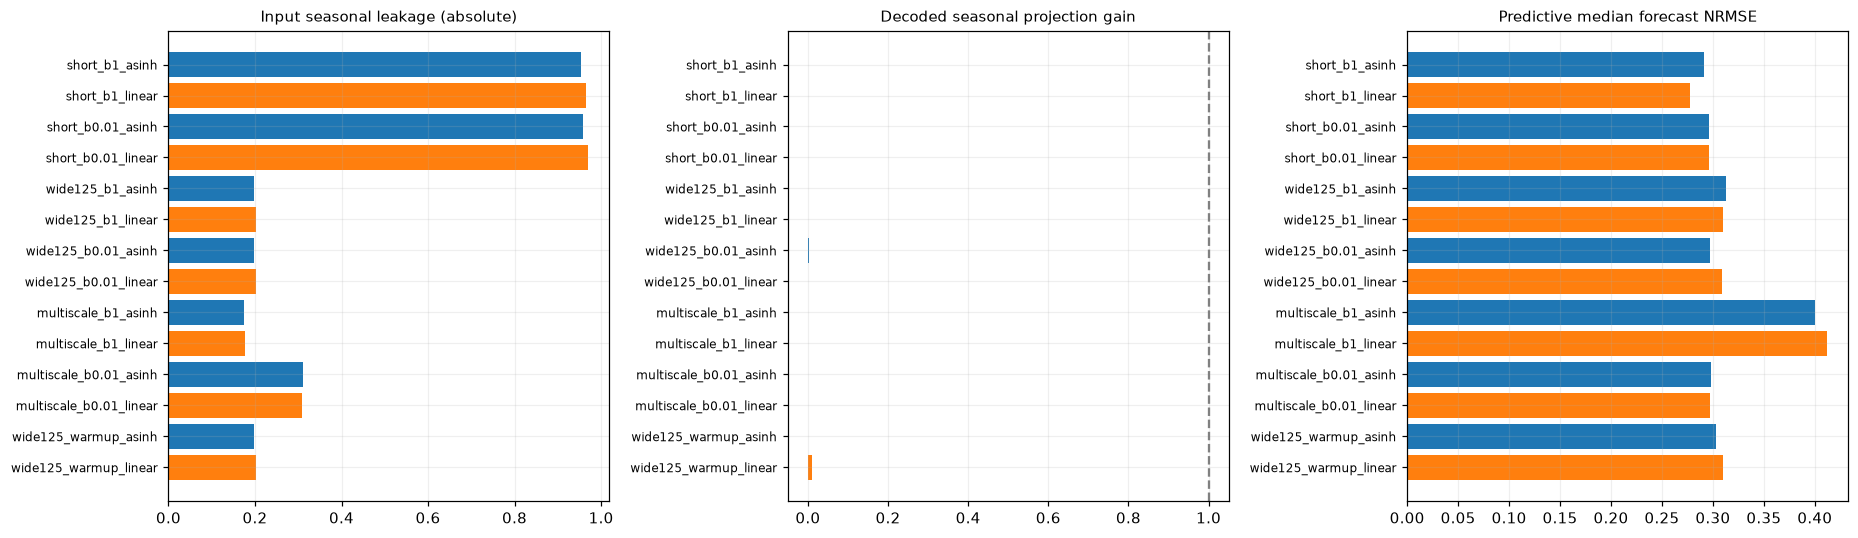

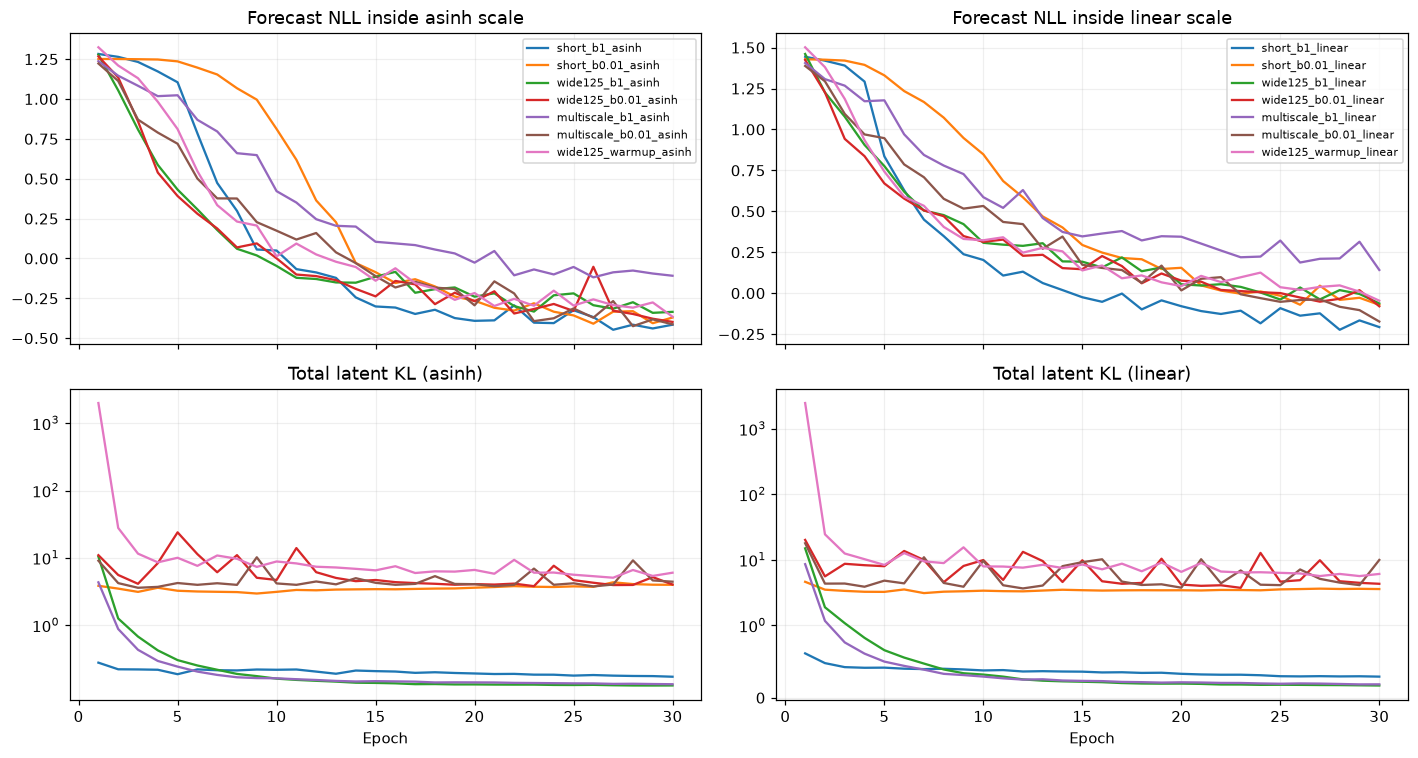

In [19]:
summary=pd.DataFrame(results)
assert len(summary)==len(VARIANTS) and summary.run.nunique()==len(VARIANTS)
main_columns=["run","input_leak_abs","input_trend_nrmse","decoded_season_gain","decoded_trend_nrmse",
              "decoded_seasonal_nrmse","seasonal_to_trend_rms","forecast_nrmse","coverage90"]
display(summary[main_columns])
display(summary[["run","val_point_nrmse","forecast_nrmse_p90","width90_scaled","kl_trend","kl_seasonal","kl_noise","kernel_weights"]])

constant=summary[summary.schedule=="constant"].copy()
effect_rows=[]
for kernel_name,normalization in product(KERNEL_SETS,["asinh","linear"]):
    a=constant[(constant.kernel==kernel_name)&(constant.normalization==normalization)&(constant.beta==1.0)].iloc[0]
    b=constant[(constant.kernel==kernel_name)&(constant.normalization==normalization)&(constant.beta==0.01)].iloc[0]
    effect_rows.append({"factor":"beta 1 -> 0.01","fixed":f"{kernel_name}/{normalization}",
                       "delta_input_leak_abs":b.input_leak_abs-a.input_leak_abs,
                       "delta_decoded_season_gain":b.decoded_season_gain-a.decoded_season_gain,
                       "delta_forecast_nrmse":b.forecast_nrmse-a.forecast_nrmse})
for kernel_name,beta in product(KERNEL_SETS,[1.0,0.01]):
    a=constant[(constant.kernel==kernel_name)&(constant.beta==beta)&(constant.normalization=="asinh")].iloc[0]
    b=constant[(constant.kernel==kernel_name)&(constant.beta==beta)&(constant.normalization=="linear")].iloc[0]
    effect_rows.append({"factor":"asinh -> linear","fixed":f"{kernel_name}/beta={beta:g}",
                       "delta_input_leak_abs":b.input_leak_abs-a.input_leak_abs,
                       "delta_decoded_season_gain":b.decoded_season_gain-a.decoded_season_gain,
                       "delta_forecast_nrmse":b.forecast_nrmse-a.forecast_nrmse})
for normalization,beta,new_kernel in product(["asinh","linear"],[1.0,0.01],["wide125","multiscale"]):
    a=constant[(constant.kernel=="short")&(constant.beta==beta)&(constant.normalization==normalization)].iloc[0]
    b=constant[(constant.kernel==new_kernel)&(constant.beta==beta)&(constant.normalization==normalization)].iloc[0]
    effect_rows.append({"factor":f"short -> {new_kernel}","fixed":f"{normalization}/beta={beta:g}",
                       "delta_input_leak_abs":b.input_leak_abs-a.input_leak_abs,
                       "delta_decoded_season_gain":b.decoded_season_gain-a.decoded_season_gain,
                       "delta_forecast_nrmse":b.forecast_nrmse-a.forecast_nrmse})
for normalization in ["asinh","linear"]:
    a=summary[(summary.kernel=="wide125")&(summary.beta==0.01)&(summary.normalization==normalization)&(summary.schedule=="constant")].iloc[0]
    b=summary[(summary.normalization==normalization)&(summary.schedule=="warmup5")].iloc[0]
    effect_rows.append({"factor":"constant beta -> warmup5","fixed":f"wide125/{normalization}",
                       "delta_input_leak_abs":b.input_leak_abs-a.input_leak_abs,
                       "delta_decoded_season_gain":b.decoded_season_gain-a.decoded_season_gain,
                       "delta_forecast_nrmse":b.forecast_nrmse-a.forecast_nrmse})
effects=pd.DataFrame(effect_rows)
display(effects)

# Парный bootstrap по тестовым сериям: характеризует тестовую выборку при данном обучении,
# НЕ разброс по seed обучения. Для эффектов beta и нормализации отдельно от изменений окон.
per_window_table=pd.DataFrame(per_window_results)
boot_rng=np.random.default_rng(SEED+80)
bootstrap_rows=[]
for kernel_name in KERNEL_SETS:
    for normalization in ["asinh","linear"]:
        a=f"{kernel_name}_b1_{normalization}"; b=f"{kernel_name}_b0.01_{normalization}"
        av=per_window_table[per_window_table.run==a].sort_values("sample").forecast_nrmse.to_numpy()
        bv=per_window_table[per_window_table.run==b].sort_values("sample").forecast_nrmse.to_numpy()
        delta=bv-av
        samples=delta[boot_rng.integers(0,len(delta),(2000,len(delta)))].mean(1)
        bootstrap_rows.append({"comparison":f"{a} -> {b}","delta_forecast_nrmse":delta.mean(),
                               "ci95_low":np.quantile(samples,0.025),"ci95_high":np.quantile(samples,0.975)})
display(pd.DataFrame(bootstrap_rows))

fig,axes=plt.subplots(1,3,figsize=(17,5))
labels=summary.run.tolist(); ypos=np.arange(len(summary))
for ax,column,title in zip(axes,["input_leak_abs","decoded_season_gain","forecast_nrmse"],
                           ["Input seasonal leakage (absolute)","Decoded seasonal projection gain","Predictive median forecast NRMSE"]):
    colors=["tab:blue" if n=="asinh" else "tab:orange" for n in summary.normalization]
    ax.barh(ypos,summary[column],color=colors)
    ax.set_yticks(ypos,labels,fontsize=8)
    ax.invert_yaxis(); ax.set_title(title,fontsize=10)
    if column=="decoded_season_gain": ax.axvline(1,color="gray",ls="--")
fig.tight_layout(); plt.show()

fig,axes=plt.subplots(2,2,figsize=(13,7),sharex=True)
for ax,norm in zip(axes[0],["asinh","linear"]):
    for v in VARIANTS:
        if v["normalization"]==norm:
            hh=histories[v["name"]]
            ax.plot(hh.epoch,hh.val_forecast_loss,label=v["name"])
    ax.set_title(f"Forecast NLL inside {norm} scale")
    ax.legend(fontsize=7)
for ax,norm in zip(axes[1],["asinh","linear"]):
    for v in VARIANTS:
        if v["normalization"]==norm:
            hh=histories[v["name"]]
            ax.plot(hh.epoch,hh.val_kl_loss,label=v["name"])
    ax.set_title(f"Total latent KL ({norm})")
    ax.set_yscale("symlog",linthresh=1)
    ax.set_xlabel("Epoch")
fig.tight_layout(); plt.show()

## 4. Графики декодеров и контрольных сигналов

Приводим baseline и изменения по одному фактору, затем комбинации и warmup.
Первая исходная Dummy-синусоида одинакова у всех запусков; значения показаны
в соответствующей нормализованной шкале, поэтому вертикальные масштабы могут отличаться.
Широкое окно должно проверяться также на истинном тренде/скачке, а не только на чистой синусоиде.

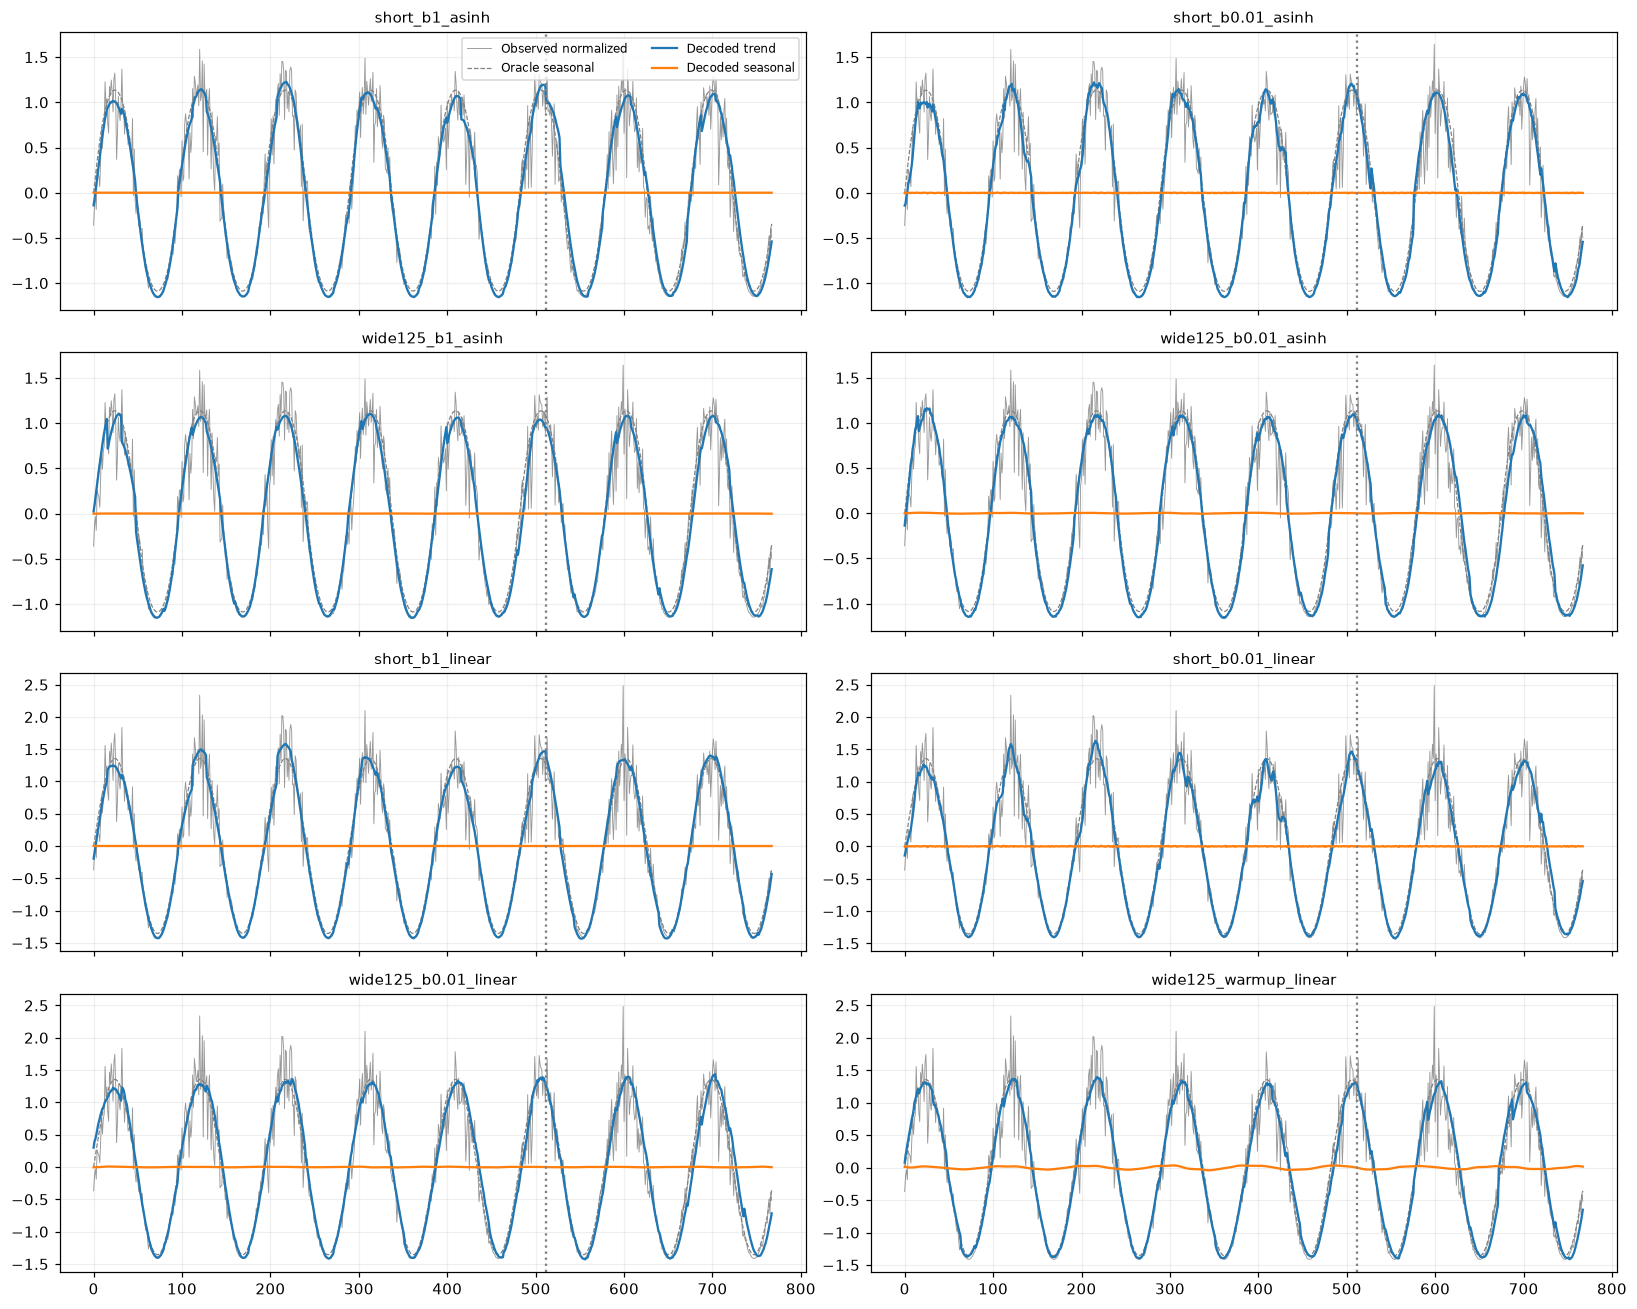

,run,case,input_leak_abs,input_trend_nrmse,decoded_season_gain,decoded_trend_nrmse
1,short_b1_asinh,sine128,0.97873,0.97899,-2.8712e-07,1.0082
2,short_b1_asinh,trend_sine_noise,0.9821,0.84964,-1.4591e-08,0.87069
5,short_b1_asinh,level_shift,0.71861,0.60758,-4.6421e-05,0.68147
7,short_b1_linear,sine128,0.97891,0.9791,3.37e-05,1.0112
8,short_b1_linear,trend_sine_noise,0.9858,0.83292,-1.7014e-08,0.84995
11,short_b1_linear,level_shift,0.71566,0.58801,8.4991e-06,0.62218
13,short_b0.01_asinh,sine128,0.98133,0.98154,0.0004979,1.0137
14,short_b0.01_asinh,trend_sine_noise,0.98468,0.85202,1.6947e-08,0.88049
17,short_b0.01_asinh,level_shift,0.75067,0.63323,-0.0063695,0.72726
19,short_b0.01_linear,sine128,0.9818,0.98195,0.00038493,0.9837


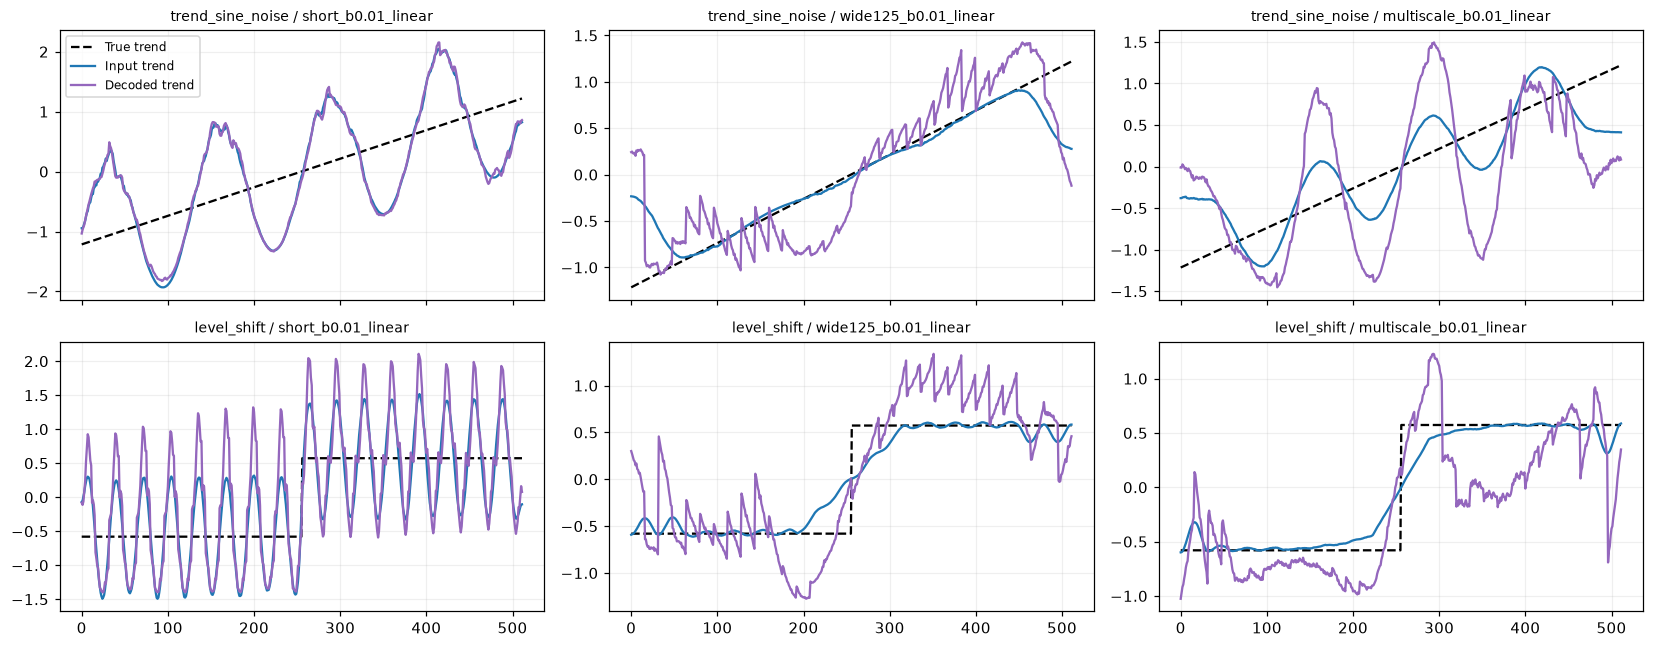

In [20]:
selected=["short_b1_asinh","short_b0.01_asinh","wide125_b1_asinh","wide125_b0.01_asinh",
          "short_b1_linear","short_b0.01_linear","wide125_b0.01_linear","wide125_warmup_linear"]
fig,axes=plt.subplots(4,2,figsize=(15,12),sharex=True)
for ax,name in zip(axes.flat,selected):
    e=visuals[name]; out=e["out"]
    ax.plot(e["full_norm"][0],color="black",alpha=0.4,lw=0.6,label="Observed normalized")
    ax.plot(e["truth"]["seasonal"][0],color="gray",ls="--",lw=0.8,label="Oracle seasonal")
    ax.plot(out["decoded_trend"][0],color="tab:blue",label="Decoded trend")
    ax.plot(out["decoded_seasonal"][0],color="tab:orange",label="Decoded seasonal")
    ax.axvline(T-0.5,color="gray",ls=":")
    ax.set_title(name,fontsize=10)
axes[0,0].legend(ncol=2,fontsize=8)
fig.tight_layout(); plt.show()
control_metrics=pd.DataFrame(trained_control_rows)
display(control_metrics[control_metrics.case.isin(["sine128","trend_sine_noise","level_shift"])][
    ["run","case","input_leak_abs","input_trend_nrmse","decoded_season_gain","decoded_trend_nrmse"]])
fig,axes=plt.subplots(2,3,figsize=(15,6),sharex=True)
for i,case in enumerate(["trend_sine_noise","level_shift"]):
    idx=control_names.index(case)
    for j,name in enumerate(["short_b0.01_linear","wide125_b0.01_linear","multiscale_b0.01_linear"]):
        e=trained_control_outputs[name]
        ax=axes[i,j]
        ax.plot(e["truth"]["trend"][idx,:T],"k--",label="True trend")
        ax.plot(e["parts"]["trend"][idx],color="tab:blue",label="Input trend")
        ax.plot(e["out"]["decoded_trend"][idx,:T],color="tab:purple",label="Decoded trend")
        ax.set_title(f"{case} / {name}",fontsize=9)
axes[0,0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. Проверки и выводы из чисел текущего запуска

Все 14 запусков используют один seed обучения. Парные сравнения позволяют отделить
эффекты настроек на этих данных, но bootstrap по сериям не заменяет повторов обучения
с несколькими seed. Периоды Dummy-генератора примерно 70–241 отсчёт; окно 125 не является
универсальным решением для всей этой области, тем более для всех реальных рядов.

По сумме прогнозов нельзя доказать, что ветви выучили физические компоненты.
Поэтому итог сохраняет и прогнозные, и компонентные метрики. Нулевая/маленькая сезонная
ветвь сама по себе ещё не доказывает posterior collapse: отдельно приведён KL каждой ветви.

In [21]:
assert NormalizationAblation._elbo_losses is DecoVAEFMLightning._elbo_losses
assert len(summary)==14 and (summary.epochs==EPOCHS).all()
for p,h in source_hashes.items():
    assert hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==h, p
for column in ["input_leak_abs","decoded_season_gain","forecast_nrmse","coverage90","kl_seasonal"]:
    assert np.isfinite(summary[column].to_numpy(dtype=float)).all(),column
# Inverse normalization и сохранение аддитивности после linear.
for norm in ["asinh","linear"]:
    probe=new_module(dict(VARIANTS[0],normalization=norm))
    xx=visual_data["context"].to(DEVICE)
    mm,ss=probe._get_normalization_stats(xx)
    torch.testing.assert_close(probe._denormalize(probe._normalize(xx,mm,ss),mm,ss),xx,rtol=1e-5,atol=0.01)
    del probe
baseline=summary[summary.run=="short_b1_asinh"].iloc[0]
# Кандидат по validation, не по test; test-результат сообщаем отдельно.
validation_candidate=summary.sort_values("val_point_nrmse").iloc[0]
best_input=summary.sort_values("input_leak_abs").iloc[0]
strongest_season=summary.sort_values("decoded_season_gain",ascending=False).iloc[0]
conclusion={"profile":RUN_PROFILE,"runs_completed":len(summary),"epochs_per_run":EPOCHS,
            "component_alignment_loss_added":False,"shared_neural_initialization_sha256":common_init_sha,
            "baseline":baseline.to_dict(),"validation_candidate":validation_candidate.to_dict(),
            "lowest_input_leakage":best_input.to_dict(),"strongest_decoded_season":strongest_season.to_dict(),
            "source_unchanged":True,"finite_outputs_and_normalization_checks":"passed"}
print(json.dumps(conclusion,indent=2,ensure_ascii=False))
print("ALL_RUNS_RESULTS_JSON="+summary.to_json(orient="records"))
report_progress({"event":"all_complete","conclusion":conclusion})
display(Markdown(
    f"**{len(summary)} запусков по {EPOCHS} эпох, {N_TEST} независимых тестовых рядов.** "
    f"Baseline: input leakage **{baseline.input_leak_abs:.3f}**, seasonal decoder gain "
    f"**{baseline.decoded_season_gain:.3g}**, forecast NRMSE **{baseline.forecast_nrmse:.3f}**. "
    f"Минимальная входная утечка у **{best_input.run}**: **{best_input.input_leak_abs:.3f}**. "
    f"Наибольший seasonal decoder gain у **{strongest_season.run}**: **{strongest_season.decoded_season_gain:.3g}**. "
    f"Кандидат по validation — **{validation_candidate.run}**; его test forecast NRMSE "
    f"**{validation_candidate.forecast_nrmse:.3f}**, coverage90 **{validation_candidate.coverage90:.3f}**. "
    "Loss для компонент отсутствует во всех вариантах."
))

{
  "profile": "full",
  "runs_completed": 14,
  "epochs_per_run": 30,
  "component_alignment_loss_added": false,
  "shared_neural_initialization_sha256": "0b8d63e85df6231893d4614d202f8f1520dc654b0996007245c589009a68114a",
  "baseline": {
    "run": "short_b1_asinh",
    "kernel": "short",
    "normalization": "asinh",
    "beta": 1.0,
    "schedule": "constant",
    "epochs": 30,
    "initial_input_leak_abs": 0.952674388885498,
    "input_leak_abs": 0.9532303810119629,
    "input_trend_gain": 0.9532303810119629,
    "input_season_gain": 0.024470554664731026,
    "input_trend_nrmse": 0.9453016519546509,
    "input_seasonal_nrmse": 0.9708524942398071,
    "input_noise_nrmse": 0.12516632676124573,
    "input_leak_abs_interior": 0.9509678483009338,
    "decoded_leak_abs": 0.9918480515480042,
    "decoded_trend_gain": 0.9918480515480042,
    "decoded_season_gain": 3.3560087331352406e-07,
    "decoded_trend_nrmse": 0.9834065437316895,
    "decoded_seasonal_nrmse": 0.9892290830612183,
    "d

<IPython.core.display.Markdown object>

## 6. Содержательные выводы текущего запуска

Этот раздел формируется из таблицы результатов и пересчитывается при повторном запуске.

In [22]:
from IPython.display import Markdown, display
base = summary.loc[summary.run == "short_b1_asinh"].iloc[0]
linear_only = summary.loc[summary.run == "short_b1_linear"].iloc[0]
wide_high = summary.loc[summary.run == "wide125_b1_asinh"].iloc[0]
wide_low = summary.loc[summary.run == "wide125_b0.01_asinh"].iloc[0]
multi_high = summary.loc[summary.run == "multiscale_b1_asinh"].iloc[0]
multi_low = summary.loc[summary.run == "multiscale_b0.01_asinh"].iloc[0]
warm_linear = summary.loc[summary.run == "wide125_warmup_linear"].iloc[0]
max_season_gain = summary.decoded_season_gain.abs().max()
relative_forecast_change = 100 * (base.forecast_nrmse-linear_only.forecast_nrmse) / base.forecast_nrmse
report_lines = [
    f"**Профиль: {RUN_PROFILE}; {len(summary)} запусков по {EPOCHS} эпох. Loss для компонент не добавлялся.**",
    "",
    f"1. **Широкие окна улучшили входную декомпозицию:** при asinh и β=1 средняя абсолютная утечка "
    f"снизилась с {base.input_leak_abs:.3f} до {wide_high.input_leak_abs:.3f} для [125] "
    f"и {multi_high.input_leak_abs:.3f} для [65,125,255]. Но этот результат не перенёсся "
    "на декодеры: трендовая ветвь продолжила восстанавливать синусоиду. На границах контекста "
    "широкий фильтр оставляет заметные искажения.",
    "",
    f"2. **Снижение KL не дало правильного разделения.** Для [125]/asinh β=0.01 улучшило "
    f"forecast NRMSE с {wide_high.forecast_nrmse:.3f} до {wide_low.forecast_nrmse:.3f}, "
    "но сезонная ветвь осталась слабой. У смеси окон оно улучшило прогноз "
    f"с {multi_high.forecast_nrmse:.3f} до {multi_low.forecast_nrmse:.3f}, одновременно "
    f"увеличив утечку с {multi_high.input_leak_abs:.3f} до {multi_low.input_leak_abs:.3f}. "
    f"Вес окна 65 вырос с 1/3 до {multi_low.kernel_weights[0]:.3f}.",
    "",
    f"3. **Линейная нормализация дала лучший прогноз на этих данных при прежних окнах и β=1:** "
    f"NRMSE {linear_only.forecast_nrmse:.3f} против {base.forecast_nrmse:.3f} "
    f"({relative_forecast_change:.1f}% уменьшение). Этот вариант также лучший по validation, "
    "но физическое разделение компонент у него не восстановилось. Для остальных окон "
    "преимущество линейной нормализации не было устойчивым.",
    "",
    f"4. **KL warmup активировал seasonal decoder сильнее в linear-варианте**, "
    f"но его gain составил лишь {warm_linear.decoded_season_gain:.4f}; для правильного "
    "восстановления oracle seasonal ожидается около 1. "
    f"Forecast NRMSE {warm_linear.forecast_nrmse:.3f}; выигрыш в прогнозе не получен.",
    "",
    f"**Максимальный модуль seasonal decoder gain среди всех вариантов: {max_season_gain:.4f}.** "
    "Если он близок к нулю, сезонная форма всё ещё преимущественно представлена трендовой ветвью. "
    "Три проверенные меры могут улучшать фильтр или прогноз, но в этом full-эксперименте "
    "они не обеспечили осмысленную выходную декомпозицию.",
    "",
    "Один seed обучения, синтетический DummyRandomDataset, фиксированные 30 эпох в full-профиле. "
    "Эти результаты не доказывают, что те же настройки будут лучшими на реальных наборах данных. "
    "Фактические версии среды и хеши текущего исходного кода сохранены в начале ноутбука."
]
if RUN_PROFILE != "full":
    report_lines.insert(0, "**SMOKE: ниже результаты короткой проверки, не выводы полного обучения.**")
display(Markdown("\n".join(report_lines)))

**Профиль: full; 14 запусков по 30 эпох. Loss для компонент не добавлялся.**

1. **Широкие окна улучшили входную декомпозицию:** при asinh и β=1 средняя абсолютная утечка снизилась с 0.953 до 0.199 для [125] и 0.174 для [65,125,255]. Но этот результат не перенёсся на декодеры: трендовая ветвь продолжила восстанавливать синусоиду. На границах контекста широкий фильтр оставляет заметные искажения.

2. **Снижение KL не дало правильного разделения.** Для [125]/asinh β=0.01 улучшило forecast NRMSE с 0.312 до 0.297, но сезонная ветвь осталась слабой. У смеси окон оно улучшило прогноз с 0.400 до 0.298, одновременно увеличив утечку с 0.174 до 0.311. Вес окна 65 вырос с 1/3 до 0.652.

3. **Линейная нормализация дала лучший прогноз на этих данных при прежних окнах и β=1:** NRMSE 0.277 против 0.291 (4.9% уменьшение). Этот вариант также лучший по validation, но физическое разделение компонент у него не восстановилось. Для остальных окон преимущество линейной нормализации не было устойчивым.

4. **KL warmup активировал seasonal decoder сильнее в linear-варианте**, но его gain составил лишь 0.0111; для правильного восстановления oracle seasonal ожидается около 1. Forecast NRMSE 0.310; выигрыш в прогнозе не получен.

**Максимальный модуль seasonal decoder gain среди всех вариантов: 0.0111.** Если он близок к нулю, сезонная форма всё ещё преимущественно представлена трендовой ветвью. Три проверенные меры могут улучшать фильтр или прогноз, но в этом full-эксперименте они не обеспечили осмысленную выходную декомпозицию.

Один seed обучения, синтетический DummyRandomDataset, фиксированные 30 эпох в full-профиле. Эти результаты не доказывают, что те же настройки будут лучшими на реальных наборах данных. Фактические версии среды и хеши текущего исходного кода сохранены в начале ноутбука.